# Censo

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq

from src import config, eda, utils, pipeline

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

In [2]:
import joblib
from src.features_static import _split_types

tr = utils.downcast(utils.load_raw("censo_train"))
y = utils.load_target()
key = utils.find_col(tr, "key", required=True)
_, cats, nums = _split_types(tr.drop(columns=[key]))
print(tr.shape, "| llaves duplicadas:", tr[key].duplicated().sum(), f"| {len(nums)} numericas, {len(cats)} nominales")

(153139, 256) | llaves duplicadas: 0 | 255 numericas, 0 nominales


## Nulos y correlación

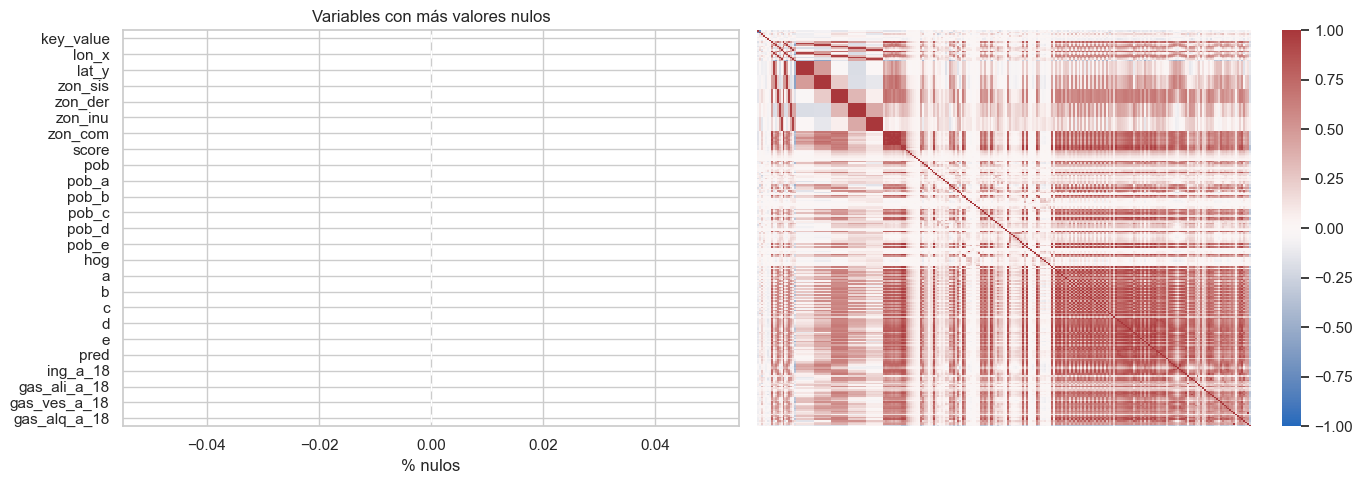

pares con |rho| > 0.95: 537 | > 0.80: 2312


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
eda.missing_plot(tr, ax=axes[0])
corr = tr[nums].corr(method="spearman")
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, ax=axes[1], xticklabels=False, yticklabels=False)
plt.tight_layout()
plt.show()
upper = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(f"pares con |rho| > 0.95: {(upper > 0.95).sum()} | > 0.80: {(upper > 0.80).sum()}")

## Construcción de variables

00:13:56 | INFO | censo: 255 numéricas, 0 categóricas, 0 fechas
00:14:44 | INFO | censo: se eliminan 107 numéricas con |corr| > 0.95
00:14:46 | INFO | censo: PCA 5 comp. explican 50.7% de la varianza
00:15:22 | INFO | CENSO listo: train (153139, 155) | test (200499, 155)


variables eliminadas por colinealidad: 107


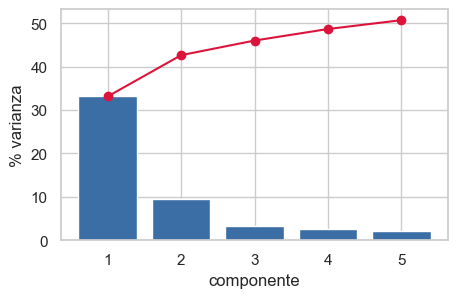

In [4]:
del tr, corr, upper
pipeline.run_static("censo")
state = joblib.load(config.MODELS_DIR / "state_censo.joblib")
print("variables eliminadas por colinealidad:", len(state["corr_drop"]))
pca = state["pca"]
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(range(1, pca.n_components_ + 1), pca.explained_variance_ratio_ * 100, color="#3b6ea5")
ax.plot(range(1, pca.n_components_ + 1), np.cumsum(pca.explained_variance_ratio_) * 100, "o-", color="crimson")
ax.set_xlabel("componente")
ax.set_ylabel("% varianza")
plt.show()

## Relación con el default

In [5]:
X, uni = eda.source_univariate("censo", y)
print(X.shape)
has = y.index.isin(X.index)
print(f"con censo: {has.mean():.1%} | default con censo {y[has].mean():.2%} | sin censo {y[~has].mean():.2%}")
uni.head(15)

(153139, 154)
con censo: 42.7% | default con censo 6.67% | sin censo 22.64%


,variable,auc_univariado,iv,nulos_pct,lectura_iv
0,censo_pc2,0.533802,0.017736,0.0,inútil
1,censo_lon_x,0.524475,0.015370,0.0,inútil
2,censo_lat_y,0.526904,0.015237,0.0,inútil
3,censo_papri,0.518678,0.014293,0.0,inútil
4,censo_pred,0.519685,0.011323,0.0,inútil
5,censo_ocup_4,0.526258,0.010256,0.0,inútil
6,censo_autten,0.520056,0.009841,0.0,inútil
7,censo_pafisis,0.525359,0.009809,0.0,inútil
8,censo_pob_a,0.515352,0.009569,0.0,inútil
9,censo_estud_10,0.520487,0.009313,0.0,inútil


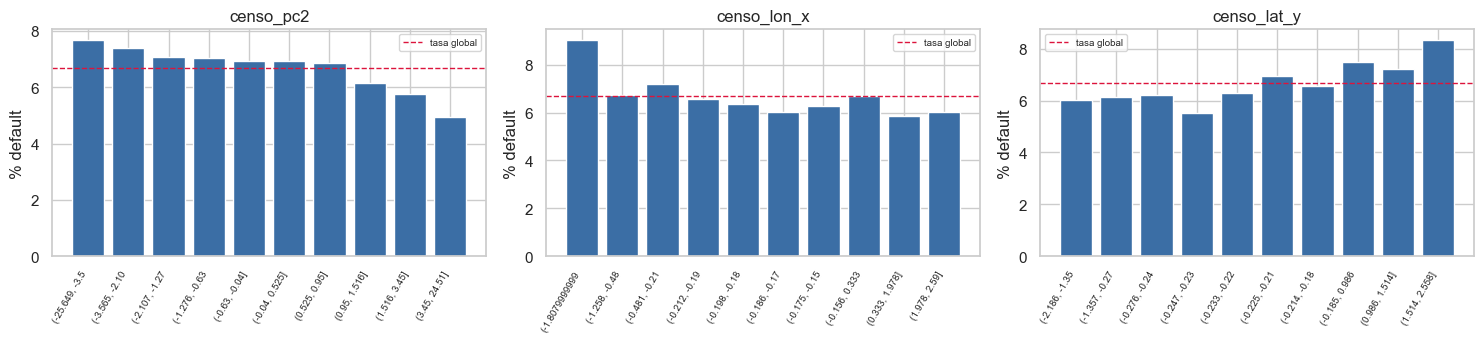

In [6]:
top = uni.variable.head(3).tolist()
idx = X.index.intersection(y.index)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, c in zip(axes, top):
    eda.default_rate_by_bin(X.loc[idx, c], y.loc[idx], ax=ax)
plt.tight_layout()
plt.show()